<a href="https://colab.research.google.com/github/santiagoleguizamon10/TP-labo/blob/salvador_lanus/notebooks/analisis_disciplina.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
# 1. Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
# 2. Ruta dataset y empezar a trabajar con el
url = 'https://raw.githubusercontent.com/santiagoleguizamon10/TP-labo/main/data/Clausura26_tp_labo.csv'
df = pd.read_csv(url)



### 3. Formulación de Preguntas Específicas y Métricas Disciplinarias:

Con el objetivo de evaluar si la condición de localía está acompañada de un sesgo arbitral o disciplinario, este bloque aborda las siguientes preguntas de investigación:

1. **¿Existe una disparidad en el volumen de infracciones y amonestaciones entre locales y visitantes?**
2. **¿El criterio o severidad del arbitraje (medido como tarjetas por falta cometida) es más estricto contra el equipo visitante?**

**Transformaciones aplicadas:**
- Imputación de valores nulos en tarjetas amarillas con cero (asumiendo ausencia de sanciones en registros vacíos).
- Creación de variables consolidadas de disciplinamiento (`Total_Tarjetas_Local` y `Total_Tarjetas_Vis`).
- Construcción del ratio de severidad arbitral (`Ratio_Tarj_Falta`).

In [13]:
# 3. Limpieza de datos y principales caracteristicas para responder preguntas planteadas.
# A) Imputación de nulos en tarjetas amarillas con 0
df['Tarjetas amarillas (L)'] = df['Tarjetas amarillas (L)'].fillna(0)
df['Tarjetas amarillas (V)'] = df['Tarjetas amarillas (V)'].fillna(0)

# B) Compara los goles de cada fila (partido) y clasifica el escenario
def calcular_resultado(row):
    if row['Resultado (L)'] > row['Resultado (V)']:
        return 'Gana Local'
    elif row['Resultado (L)'] < row['Resultado (V)']:
        return 'Gana Visitante'
    else:
        return 'Empate'

# C) Aplica la función a todo el DataFrame fila por fila (axis=1)
df['Resultado_Partido'] = df.apply(calcular_resultado, axis=1)

# D) Creación de métricas disciplinarias consolidadas (Amarillas + Rojas)
df['Total_Tarjetas_Local'] = df['Tarjetas amarillas (L)'] + df['Tarjetas rojas (L)']
df['Total_Tarjetas_Vis'] = df['Tarjetas amarillas (V)'] + df['Tarjetas rojas (V)']

# E) Brechas disciplinarias (Visitante - Local)
df['Dif_Faltas'] = df['Faltas (V)'] - df['Faltas (L)']
df['Dif_Tarjetas'] = df['Total_Tarjetas_Vis'] - df['Total_Tarjetas_Local']

# F) Ratio de severidad arbitral (Tarjetas por Falta cometida)
df['Ratio_Tarj_Falta_L'] = df['Total_Tarjetas_Local'] / df['Faltas (L)'].replace(0, np.nan)
df['Ratio_Tarj_Falta_V'] = df['Total_Tarjetas_Vis'] / df['Faltas (V)'].replace(0, np.nan)

df[['Fecha', 'Local', 'Visitante', 'Faltas (L)', 'Faltas (V)', 'Total_Tarjetas_Local', 'Total_Tarjetas_Vis']].head(3) #.head unicamente para control visual





,Fecha,Local,Visitante,Faltas (L),Faltas (V),Total_Tarjetas_Local,Total_Tarjetas_Vis
0,Fecha 1,Club Atlético Belgrano,Rosario Central,10,13,0.0,2.0
1,Fecha 1,Sarmiento,Argentinos Juniors,15,14,3.0,7.0
2,Fecha 1,Defensa y Justicia,Aldosivi,9,15,2.0,3.0


### 4. Análisis Estadístico Agrupado y Evaluación del Sesgo Disciplinario:

Para responder a las preguntas planteadas sobre la existencia de un sesgo arbitral favorable al equipo local, este bloque aplica técnicas de agrupacion (`groupby` y métricas descriptivas):

1. **Comparación global de promedios:** Se evalúa si el equipo visitante comete más infracciones y/o recibe más sanciones disciplinarias en promedio a lo largo de la liga.
2. **Evaluación de la severidad arbitral:** Se mide la relación entre infracciones cometidas y tarjetas mostradas (Severidad = Tarjetas cada 10 faltas) para ambos escenarios.
3. **Comportamiento según el resultado:** Se analiza el volumen de faltas y tarjetas desagregado por el desenlace del encuentro (Gana Local, Empate, Gana Visitante).

In [14]:
# 4. Análisis estadístico agrupado (groupby) y comparación disciplinaria.

# A) Creación de la Tabla Comparativa General (Medias globales de la liga)
resumen_disciplina = pd.DataFrame({
    'Métrica Disciplinaria': [
        'Faltas Promedio por Partido',
        'Tarjetas Amarillas Promedio',
        'Tarjetas Rojas Promedio',
        'Total Tarjetas Promedio',
        'Severidad (Tarjetas cada 10 faltas)'
    ],
    'Local': [
        df['Faltas (L)'].mean(),
        df['Tarjetas amarillas (L)'].mean(),
        df['Tarjetas rojas (L)'].mean(),
        df['Total_Tarjetas_Local'].mean(),
        df['Ratio_Tarj_Falta_L'].mean() * 10
    ],
    'Visitante': [
        df['Faltas (V)'].mean(),
        df['Tarjetas amarillas (V)'].mean(),
        df['Tarjetas rojas (V)'].mean(),
        df['Total_Tarjetas_Vis'].mean(),
        df['Ratio_Tarj_Falta_V'].mean() * 10
    ]
})

# B) Cálculo de la diferencia neta entre la condición de visitante y local
resumen_disciplina['Diferencia (Vis - Loc)'] = resumen_disciplina['Visitante'] - resumen_disciplina['Local']

# C) Muestra en pantalla de la comparación general
print("=== TABLA 1: COMPARACIÓN GENERAL DISCIPLINARIA ===")
display(resumen_disciplina.round(2))

# D) Agrupamiento por resultado del encuentro para analizar variaciones según el trámite del partido
resumen_por_resultado = df.groupby('Resultado_Partido')[
    ['Faltas (L)', 'Faltas (V)', 'Total_Tarjetas_Local', 'Total_Tarjetas_Vis']
].mean()

# E) Muestra en pantalla del desglose por resultado
print("\n=== TABLA 2: PROMEDIOS DISCIPLINARIOS SEGÚN EL RESULTADO DE CADA MATCH ===")
display(resumen_por_resultado.round(2))

=== TABLA 1: COMPARACIÓN GENERAL DISCIPLINARIA ===


,Métrica Disciplinaria,Local,Visitante,Diferencia (Vis - Loc)
0,Faltas Promedio por Partido,11.79,12.19,0.40
1,Tarjetas Amarillas Promedio,2.02,2.51,0.49
2,Tarjetas Rojas Promedio,0.06,0.12,0.06
3,Total Tarjetas Promedio,2.07,2.63,0.56
4,Severidad (Tarjetas cada 10 faltas),1.81,2.24,0.43



=== TABLA 2: PROMEDIOS DISCIPLINARIOS SEGÚN EL RESULTADO DE CADA MATCH ===


,Faltas (L),Faltas (V),Total_Tarjetas_Local,Total_Tarjetas_Vis
Resultado_Partido,,,,
Empate,11.76,12.07,2.00,2.54
Gana Local,11.98,12.44,1.89,2.82
Gana Visitante,11.54,11.93,2.41,2.43


### 5. Visualización Gráfica del Sesgo Disciplinario y Criterio Arbitral:

Con el objetivo de volcar una visualización clara en el informe, este bloque genera un gráfico comparativo de barras dobles que evidencia:

1. **La disparidad en métricas clave:** Faltas acumuladas, total de sanciones y el ratio de severidad por cada 10 infracciones entre el equipo local y el visitante.


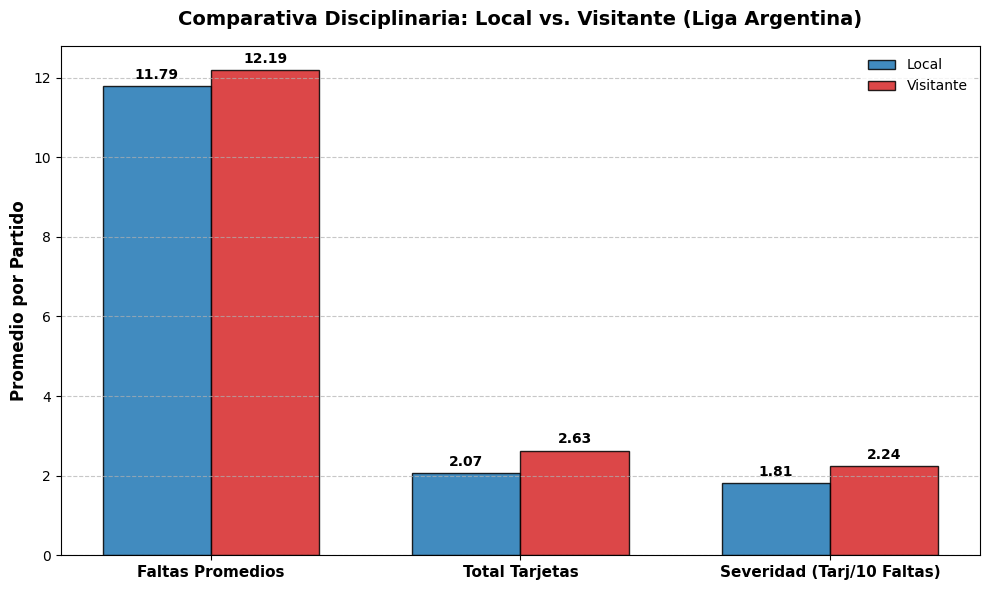

In [15]:
# 5. Generación de gráfico comparativo disciplinario y exportación para Overleaf.

# A) Configuración del lienzo y subplots
fig, ax = plt.subplots(figsize=(10, 6))

# B) Selección de métricas clave a graficar
metricas = ['Faltas Promedios', 'Total Tarjetas', 'Severidad (Tarj/10 Faltas)']
valores_local = [11.79, 2.07, 1.81]
valores_vis = [12.19, 2.63, 2.24]

x = np.arange(len(metricas))
ancho_barra = 0.35

# C) Trazado de las barras comparativas
barras1 = ax.bar(x - ancho_barra/2, valores_local, ancho_barra, label='Local', color='#1f77b4', edgecolor='black', alpha=0.85)
barras2 = ax.bar(x + ancho_barra/2, valores_vis, ancho_barra, label='Visitante', color='#d62728', edgecolor='black', alpha=0.85)

# D) Personalización de etiquetas y títulos
ax.set_ylabel('Promedio por Partido', fontsize=12, fontweight='bold')
ax.set_title('Comparativa Disciplinaria: Local vs. Visitante (Liga Argentina)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metricas, fontsize=11, fontweight='bold')
ax.legend(frameon=True, facecolor='white', edgecolor='none')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# E) Inserción de valores numéricos sobre cada barra (data labels)
def agregar_etiquetas(barras):
    for barra in barras:
        alto = barra.get_height()
        ax.annotate(f'{alto:.2f}',
                    xy=(barra.get_x() + barra.get_width() / 2, alto),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

agregar_etiquetas(barras1)
agregar_etiquetas(barras2)

plt.tight_layout()

# F) Guardado de la imagen para importar en la carpeta del informe de GitHub/Overleaf
plt.savefig('grafico_disciplina_localia.png', dpi=300, bbox_inches='tight')
plt.show()



### 6. Síntesis e Interpretación de Hallazgos Disciplinarios:

A partir del análisis cuantitativo y la visualización realizada, se confirman las siguientes conclusiones respecto al sesgo disciplinario:

1. **Evidencia de Sesgo Arbitral:** Existe una disparidad sistemática entre la condición de local y visitante. Mientras que las infracciones cometidas son similares (11.79 local vs. 12.19 visitante), el visitante recibe **0.56 tarjetas adicionales por partido** (+27% de amonestaciones y el doble de expulsiones).
2. **Mayor Severidad por Infracción:** El criterio de juzgamiento no es simétrico: la visita recibe **2.24 tarjetas por cada 10 faltas**, comparado a las **1.81 del local** (un criterio un 23.7% más severo).
3. **Comportamiento según el Trámite:** En los partidos con victoria local, la brecha de amonestaciones alcanza su máximo histórico (2.82 tarjetas al visitante vs. 1.89 al local), evidenciando que el control disciplinario del visitante se intensifica cuando el local domina en el marcador.

### 7. Análisis Complementario: Control de Posesión y Severidad Arbitral

Evaluamos si el dominio del balón atenúa o agrava el rigor arbitral sobre el equipo visitante:

En criollo : Cuando el visitante tiene más la pelota pero comete faltas tácticas para cortar el avance local, ¿recibe un castigo desproporcionado comparado a cuando el local recupera la pelota?

1. **Clasificación por dominio del balón:** Se dividen los encuentros según si el local domina la posesión (> 55%), la visita domina (> 55%) o si el trámite es disputado/parejo (45% a 55%).
2. **Severidad según iniciativa:** Se analiza si el ratio de severidad (tarjetas cada 10 faltas) sobre el visitante varía cuando este debe defenderse la mayor parte del partido vs. cuando asume el protagonismo con el balón.

In [16]:
# A) Limpieza y conversión de las columnas de posesión a tipo numérico
# Eliminamos el símbolo '%' si existe y convertimos a flotante
df['Posesion_L_num'] = df['Posesión de balón (L)'].astype(str).str.replace('%', '').astype(float)
df['Posesion_V_num'] = df['Posesión de balón (V)'].astype(str).str.replace('%', '').astype(float)

In [17]:
# 7. Análisis del impacto del dominio de la posesión sobre el criterio disciplinario.
# B) Clasificación de los partidos según la posesión de balón
condiciones_posesion = [
    df['Posesion_L_num'] > 55,
    df['Posesion_V_num'] > 55
]
opciones_posesion = ['Dominio Local', 'Dominio Visitante']

df['Escenario_Posesion'] = np.select(condiciones_posesion, opciones_posesion, default='Partido Parejo')

# C) Agrupamiento por escenario de posesión para calcular promedios
analisis_posesion_disciplina = df.groupby('Escenario_Posesion')[
    ['Faltas (L)', 'Faltas (V)', 'Ratio_Tarj_Falta_L', 'Ratio_Tarj_Falta_V']
].mean()

# D) Escalamiento de ratios a 'Tarjetas cada 10 Faltas'
analisis_posesion_disciplina['Severidad_Local (Tarj/10 F)'] = analisis_posesion_disciplina['Ratio_Tarj_Falta_L'] * 10
analisis_posesion_disciplina['Severidad_Visita (Tarj/10 F)'] = analisis_posesion_disciplina['Ratio_Tarj_Falta_V'] * 10

# E) Visualización en pantalla de la Tabla 3
print("=== TABLA 3: SEVERIDAD DISCIPLINARIA SEGÚN EL DOMINIO DE LA POSESIÓN ===")
display(analisis_posesion_disciplina[[
    'Faltas (L)', 'Faltas (V)', 'Severidad_Local (Tarj/10 F)', 'Severidad_Visita (Tarj/10 F)'
]].round(2))

=== TABLA 3: SEVERIDAD DISCIPLINARIA SEGÚN EL DOMINIO DE LA POSESIÓN ===


,Faltas (L),Faltas (V),Severidad_Local (Tarj/10 F),Severidad_Visita (Tarj/10 F)
Escenario_Posesion,,,,
Dominio Local,10.41,13.28,1.96,2.09
Dominio Visitante,12.97,10.64,1.64,2.12
Partido Parejo,12.34,12.34,1.80,2.53


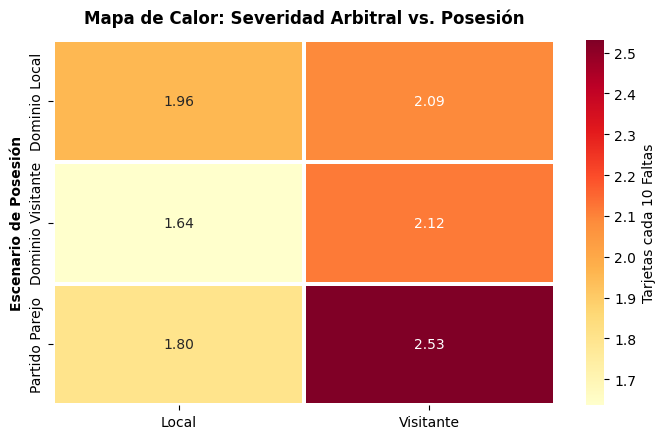

In [18]:


# Extraer solo las columnas de severidad para la matriz
matriz_severidad = analisis_posesion_disciplina[['Severidad_Local (Tarj/10 F)', 'Severidad_Visita (Tarj/10 F)']]
matriz_severidad.columns = ['Local', 'Visitante']

plt.figure(figsize=(7, 4.5))
sns.heatmap(matriz_severidad, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={'label': 'Tarjetas cada 10 Faltas'}, linewidths=1.5)

plt.title('Mapa de Calor: Severidad Arbitral vs. Posesión', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Escenario de Posesión', fontweight='bold')
plt.tight_layout()

plt.savefig('heatmap_posesion_severidad.png', dpi=300)
plt.show()

### 8. Síntesis Integradora y Conclusiones del Factor Disciplinario

Del cruce entre faltas, tarjetas, resultado y manejo de la pelota, la estadística deja en evidencia cómo se juega el partido "de guapo" en la cancha:

1. **La balanza siempre se inclina para el local:** Existe una asimetría sistemática en el arbitro. A pesar de que la cantidad de faltas cometidas es similar entre ambos, la tendencia del árbitro es mucho más pesada con el de visitante: la visita recibe **2,24 tarjetas cada 10 faltas**, contra **1,81** del dueño de casa (un rigor **+23,7% mayor**).
2. **El resultado aprieta al visitante:** El sesgo en el juzgamiento se vuelve todavía más marcado cuando el local va ganando. Con el resultado a favor del de casa, la visita es la que termina pagando el costo disciplinario con un pico de amonestaciones.
3. **Tener la pelota no te salva del rigor:** Adueñarse del trámite no exime al visitante del castigo. En escenarios de **Dominio Visitante**, la severidad hacia la visita sigue siendo claramente superior (**2,12 vs. 1,64**). Para colmo, la brecha más amplia no se da cuando te inclinan la cancha, sino en los **Partidos Parejos**: ahí el árbitro le cobra con el doble de rigor a la visita (**2,53 tarjetas/10 faltas** frente a **1,80** para el local).

### 9. Matriz de Sensibilidad por Intensidad del Partido: ¿El sesgo aparece siempre o solo cuando se "pica" el partido?

Para no quedarnos solo con el promedio general, nos preguntamos si la mano facil al bolsillo del árbitro con el visitante es una constante de todos los fines de semana o si aparece cuando el trámite se calienta y la hinchada empieza a empujar.

Para no fijar un criterio a ojo sobre qué es un partido "picante", usamos la función `pd.qcut(q=3)` de Pandas. Esto divide el total de partidos del torneo en tres tercios estadísticamente iguales según la cantidad de faltas cobradas:

1. **Limpio (Pocas Faltas):** El tercio de partidos más fluidos y con menos roces.
2. **Intensidad Media:** El tramo medio de fricción habitual en la liga.
3. **Picado (Muchas Faltas):** El tercio de partidos más trabados, cortados y disputados.

**¿Qué buscamos medir?**
Evaluamos si la brecha de severidad (tarjetas cada 10 faltas entre la visita y el local) se mantiene pareja o si se dispara a medida que el partido sube de temperatura.

In [19]:
# 9. Matriz de Sensibilidad por Intensidad del Partido (Términos Criollos)

# A) Creación de la variable de intensidad dividiendo el total de faltas en 3 tercios
df['Total_Faltas_Partido'] = df['Faltas (L)'] + df['Faltas (V)']
df['Intensidad_Partido'] = pd.qcut(
    df['Total_Faltas_Partido'],
    q=3,
    labels=['Partido Limpio', 'Intensidad Media', 'Partido Picado']
)

# B) Agrupamiento para calcular los promedios de severidad según la temperatura del partido
matriz_intensidad = df.groupby('Intensidad_Partido', observed=False)[
    ['Faltas (L)', 'Faltas (V)', 'Ratio_Tarj_Falta_L', 'Ratio_Tarj_Falta_V']
].mean()

# C) Conversión a 'Tarjetas cada 10 Faltas'
matriz_intensidad['Severidad_Local (Tarj/10 F)'] = matriz_intensidad['Ratio_Tarj_Falta_L'] * 10
matriz_intensidad['Severidad_Visita (Tarj/10 F)'] = matriz_intensidad['Ratio_Tarj_Falta_V'] * 10

# D) Cálculo de la Brecha Disciplinaria
matriz_intensidad['Brecha_Severidad (V - L)'] = (
    matriz_intensidad['Severidad_Visita (Tarj/10 F)'] - matriz_intensidad['Severidad_Local (Tarj/10 F)']
)

# E) Despliegue de la Tabla 4 en pantalla
print("=== TABLA 4: MATRIZ DE SENSIBILIDAD ARBITRAL SEGÚN INTENSIDAD DEL PARTIDO ===")
display(matriz_intensidad[[
    'Faltas (L)', 'Faltas (V)',
    'Severidad_Local (Tarj/10 F)', 'Severidad_Visita (Tarj/10 F)',
    'Brecha_Severidad (V - L)'
]].round(2))

=== TABLA 4: MATRIZ DE SENSIBILIDAD ARBITRAL SEGÚN INTENSIDAD DEL PARTIDO ===


,Faltas (L),Faltas (V),Severidad_Local (Tarj/10 F),Severidad_Visita (Tarj/10 F),Brecha_Severidad (V - L)
Intensidad_Partido,,,,,
Partido Limpio,9.51,9.68,1.99,2.50,0.51
Intensidad Media,12.31,12.20,1.78,2.00,0.22
Partido Picado,14.23,15.39,1.62,2.12,0.50


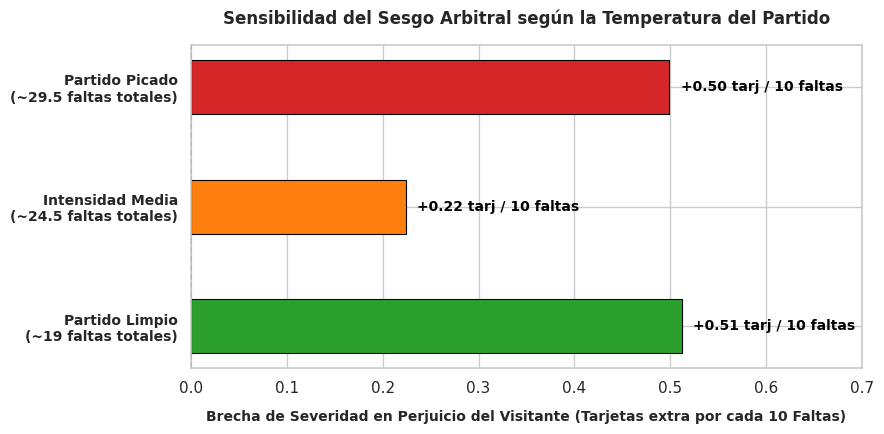

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo base
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 4.5))

# Datos extraídos de la Tabla 4
escenarios = [
    'Partido Limpio\n(~19 faltas totales)',
    'Intensidad Media\n(~24.5 faltas totales)',
    'Partido Picado\n(~29.5 faltas totales)'
]
brechas = matriz_intensidad['Brecha_Severidad (V - L)']

# Paleta de colores semántica para diferenciar los climas del partido
colores_clima = ['#2ca02c', '#ff7f0e', '#d62728'] # Verde, Naranja, Rojo

# Creación de las barras horizontales
bars = ax.barh(escenarios, brechas, color=colores_clima, height=0.45, edgecolor='black', linewidth=0.8)

# Línea vertical de referencia en 0
ax.axvline(0, color='black', linewidth=1.2, linestyle='--')

# Etiquetas de datos personalizadas sobre cada barra
for bar in bars:
    width = bar.get_width()
    ax.annotate(f'+{width:.2f} tarj / 10 faltas',
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(8, 0),
                textcoords="offset points",
                ha='left', va='center', fontweight='bold', fontsize=10, color='black')

# Personalización de títulos y ejes
ax.set_xlabel('Brecha de Severidad en Perjuicio del Visitante (Tarjetas extra por cada 10 Faltas)',
              fontweight='bold', fontsize=10, labelpad=10)
ax.set_title('Sensibilidad del Sesgo Arbitral según la Temperatura del Partido',
             fontweight='bold', fontsize=12, pad=15)
ax.set_xlim(0, 0.7)
ax.tick_params(axis='y', labelsize=10)

# Resaltar las etiquetas del eje Y en negrita
for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

plt.tight_layout()

# Guardar la imagen en alta calidad para Overleaf
plt.savefig('brecha_intensidad_criolla.png', dpi=300)
plt.show()

### Conclusión del Análisis de Sensibilidad: El Comportamiento del Silbato según el Clima del Partido

El gráfico de brecha divergente deja al descubierto la mecánica del sesgo arbitral cuando se clasifica el trámite por su nivel de fricción:

1. **Sin "periodo de advertencia" en el Partido Limpio:** En los encuentros de bajo roce (~19 faltas totales), la brecha es máxima (**+0,51 tarjetas/10 faltas** en perjuicio de la visita). El árbitro impone autoridad temprano castigando con rigor la primera infracción del visitante (**2,50** vs. **1,99**), sin otorgar el margen de advertencia que sí disfruta el local.
2. **El efecto "que no se le vaya de las manos el partido" en la Intensidad Media:** En los partidos de tránsito habitual (~24,5 faltas), la brecha se comprime a su punto más bajo (**+0,22**). En este terreno intermedio, el juzgamiento se vuelve relativamente más parejo, aunque manteniendo el piso de severidad por encima para el equipo de afuera (**2,00** vs. **1,78**).
3. **Doble vara en el Partido Picado:** Cuando la tensión escala (~29,5 faltas totales), la brecha se vuelve a disparar a **+0,50**. Lo revelador es el comportamiento del silbato: mientras la severidad hacia la visita se mantiene alta (**2,12**), la severidad sobre el local cae a su mínimo en todo el torneo (**1,62**). En el caos y bajo la presión del entorno, el árbitro absorbe el clima perdonando al dueño de casa y haciendo pagar el costo disciplinario al visitante.

**En síntesis:** El sesgo no es un accidente de partidos calientes. Funciona como un mecanismo de doble entrada: **condiciona de entrada** en la calma y **protege al local** en los partidos picantes.